<a href="https://colab.research.google.com/github/Pineapp1e-pie/recommender-systems-research/blob/main/NIR_Recommender_Systems_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# НИР: исследование методов рекомендаций при ограниченном объёме пользовательских данных

**Набор данных:** MovieLens 100K  
**Методы:** Popularity-based, User-based CF, FunkSVD, User-CF + fallback  
**Доли обучающих данных:** 10%, 25%, 50%, 100%  
**Повторы:** 5  
**Метрики:** Recall@10, NDCG@10, Catalog Coverage

Ноутбук пересчитывает эксперимент с нуля. Ранее полученные численные результаты не используются.

**Ключевое правило:** при формировании рекомендаций для пользователя исключаются все фильмы из его полной обучающей истории (`train_full`), даже если модель обучена только на 10%, 25% или 50% оценок.

## 1. Библиотеки и параметры

In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

SEED = 42
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
ZIP_PATH = DATA_DIR / "ml-100k.zip"
EXTRACT_DIR = DATA_DIR / "ml-100k"

DATA_SHARES = [0.10, 0.25, 0.50, 1.00]
N_REPEATS = 5
TOP_N = 10
RELEVANT_THRESHOLD = 4

# Параметры User-based CF, зафиксированные в методике НИР
N_NEIGHBORS = 20
MIN_NEIGHBORS_PER_ITEM = 5

# Параметры FunkSVD, зафиксированные в методике НИР
SVD_FACTORS = 50
SVD_LEARNING_RATE = 0.01
SVD_REGULARIZATION = 0.02
SVD_EPOCHS = 20

METHODS = [
    "Popularity-based",
    "User-based CF",
    "FunkSVD",
    "User-CF + fallback",
]

print("Параметры заданы.")

Параметры заданы.


## 2. Загрузка MovieLens 100K

In [2]:
if not ZIP_PATH.exists():
    print("Загружаем MovieLens 100K...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_DIR)

ratings = pd.read_csv(
    EXTRACT_DIR / "u.data",
    sep="\\t",
    names=["user_id", "movie_id", "rating", "timestamp"],
    engine="python"
)

movies = pd.read_csv(
    EXTRACT_DIR / "u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["movie_id", "title"]
)

ratings["user_id"] = ratings["user_id"].astype(int)
ratings["movie_id"] = ratings["movie_id"].astype(int)
ratings["rating"] = ratings["rating"].astype(float)

all_users = sorted(ratings["user_id"].unique())
all_movies = sorted(movies["movie_id"].unique())
all_movie_set = set(all_movies)

print(f"Оценок: {len(ratings):,}")
print(f"Пользователей: {len(all_users)}")
print(f"Фильмов в каталоге: {len(all_movies)}")
display(ratings.head())
display(movies.head())

Загружаем MovieLens 100K...
Оценок: 100,000
Пользователей: 943
Фильмов в каталоге: 1682


,user_id,movie_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


## 3. Первичный анализ данных

In [3]:
print("Пропуски:")
display(ratings.isna().sum().to_frame("Количество"))

duplicate_count = ratings.duplicated(["user_id", "movie_id"]).sum()
print("Дубликаты пар пользователь–фильм:", duplicate_count)

print("Распределение оценок:")
display(ratings["rating"].value_counts().sort_index().to_frame("Количество"))

display(ratings.groupby("user_id")["rating"].size().describe().to_frame("Оценок на пользователя"))

Пропуски:


,Количество
user_id,0
movie_id,0
rating,0
timestamp,0


Дубликаты пар пользователь–фильм: 0
Распределение оценок:


,Количество
rating,
1.0,6110
2.0,11370
3.0,27145
4.0,34174
5.0,21201


,Оценок на пользователя
count,943.000000
mean,106.044539
std,100.931743
min,20.000000
25%,33.000000
50%,65.000000
75%,148.000000
max,737.000000


## 4. Разбиение на обучающую и тестовую выборки

Для каждого пользователя отдельно выделяется 80% оценок в обучение и 20% в тест. Разбиение фиксировано и не меняется между сценариями.

In [4]:
from sklearn.model_selection import train_test_split

train_parts, test_parts = [], []

for user_id, user_data in ratings.groupby("user_id"):
    user_train, user_test = train_test_split(
        user_data,
        test_size=0.2,
        random_state=SEED
    )
    train_parts.append(user_train)
    test_parts.append(user_test)

train_full = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

print(f"Обучающая выборка: {len(train_full):,}")
print(f"Тестовая выборка: {len(test):,}")
print(f"Пользователей в обучении: {train_full.user_id.nunique()}")
print(f"Пользователей в тесте: {test.user_id.nunique()}")

Обучающая выборка: 79,619
Тестовая выборка: 20,381
Пользователей в обучении: 943
Пользователей в тесте: 943


## 5. Полная история пользователей и тестовая релевантность

История просмотренных фильмов берётся из `train_full`, а не из сокращённой подвыборки. Это предотвращает повторную рекомендацию уже оценённых фильмов.

In [5]:
train_items = (
    train_full.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

relevant_test_items = (
    test[test["rating"] >= RELEVANT_THRESHOLD]
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

eval_users = sorted(
    uid for uid in all_users
    if relevant_test_items.get(uid)
)

candidate_items = {
    uid: all_movie_set - train_items.get(uid, set())
    for uid in all_users
}

print(f"Пользователей с релевантными фильмами в тесте: {len(eval_users)}")

for uid in eval_users:
    assert train_items[uid].isdisjoint(candidate_items[uid])
    assert relevant_test_items[uid].issubset(candidate_items[uid])

Пользователей с релевантными фильмами в тесте: 929


## 6. Сокращение обучающей выборки

Для каждого пользователя сохраняется заданная доля оценок, но не менее одной. Пять повторов используют разные фиксированные seed. При 100% используется полный `train_full`.

In [6]:
def make_sampled_train(train_data, share, random_state):
    sampled_parts = []

    for user_id, user_data in train_data.groupby("user_id"):
        if share >= 1.0:
            user_sample = user_data.copy()
        else:
            n_keep = max(1, int(np.ceil(len(user_data) * share)))
            user_sample = user_data.sample(
                n=n_keep,
                random_state=random_state
            )
        sampled_parts.append(user_sample)

    return pd.concat(sampled_parts, ignore_index=True)

## 7. Метод 1 — Popularity-based

Фильмы сортируются по числу оценок, затем по средней оценке. При равенстве используется `movie_id` для воспроизводимого порядка.

In [7]:
def build_popularity_ranking(train_data):
    stats = (
        train_data.groupby("movie_id")["rating"]
        .agg(rating_count="count", average_rating="mean")
        .reset_index()
    )

    stats = (
        pd.DataFrame({"movie_id": all_movies})
        .merge(stats, on="movie_id", how="left")
    )
    stats["rating_count"] = stats["rating_count"].fillna(0)
    stats["average_rating"] = stats["average_rating"].fillna(0)

    ranked = stats.sort_values(
        ["rating_count", "average_rating", "movie_id"],
        ascending=[False, False, True],
        kind="mergesort"
    )
    return ranked["movie_id"].tolist()


def recommend_popularity(ranking, user_id, top_n=TOP_N):
    seen = train_items.get(user_id, set())
    candidates = candidate_items[user_id]
    return [mid for mid in ranking if mid in candidates][:top_n]

## 8. Метод 2 — User-based Collaborative Filtering

Косинусное сходство рассчитывается по векторам оценок. Для прогноза используется взвешенная средняя оценка до 20 ближайших соседей. Фильм включается в персональный список, если его оценили не менее 5 выбранных соседей.

In [8]:
def recommend_user_cf_all(
    train_data,
    target_users,
    top_n=TOP_N,
    n_neighbors=N_NEIGHBORS,
    min_neighbors_per_item=MIN_NEIGHBORS_PER_ITEM
):
    rating_matrix = (
        train_data.pivot_table(
            index="user_id",
            columns="movie_id",
            values="rating",
            aggfunc="mean"
        )
        .reindex(index=all_users, columns=all_movies)
        .fillna(0.0)
    )

    matrix = rating_matrix.to_numpy(dtype=float)
    similarities = cosine_similarity(matrix)

    user_to_idx = {uid: idx for idx, uid in enumerate(all_users)}
    recommendations = {}

    for uid in target_users:
        u_idx = user_to_idx[uid]
        sims = similarities[u_idx].copy()
        sims[u_idx] = 0.0

        # Стабильная сортировка: сначала сходство по убыванию,
        # при равенстве — индекс пользователя по возрастанию.
        neighbor_order = np.lexsort((np.arange(len(all_users)), -sims))
        neighbor_order = [
            j for j in neighbor_order
            if sims[j] > 0
        ][:n_neighbors]

        if not neighbor_order:
            recommendations[uid] = []
            continue

        neighbor_sims = sims[neighbor_order]
        neighbor_ratings = matrix[neighbor_order, :]
        rated_mask = neighbor_ratings > 0

        weighted_sum = (neighbor_ratings * neighbor_sims[:, None]).sum(axis=0)
        similarity_sum = (rated_mask * neighbor_sims[:, None]).sum(axis=0)
        neighbor_counts = rated_mask.sum(axis=0)

        scores = np.divide(
            weighted_sum,
            similarity_sum,
            out=np.full(len(all_movies), np.nan, dtype=float),
            where=similarity_sum > 0
        )

        seen = train_items.get(uid, set())
        candidates = candidate_items[uid]

        scored_items = []
        for movie_idx, movie_id in enumerate(all_movies):
            if movie_id not in candidates:
                continue
            if neighbor_counts[movie_idx] < min_neighbors_per_item:
                continue
            if np.isfinite(scores[movie_idx]):
                scored_items.append((movie_id, scores[movie_idx]))

        scored_items.sort(key=lambda x: (-x[1], x[0]))
        recommendations[uid] = [mid for mid, _ in scored_items[:top_n]]

    return recommendations

## 9. Метод 3 — FunkSVD

Используется регуляризованная матричная факторизация, обучаемая только на наблюдаемых оценках. Прогноз включает глобальное среднее, смещения пользователя и фильма, а также скалярное произведение латентных факторов:

\[
\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i.
\]

Параметры соответствуют описанию методики: 50 факторов, learning rate 0,01, регуляризация 0,02, 20 эпох.

In [9]:
class FunkSVD:
    def __init__(
        self,
        n_factors=SVD_FACTORS,
        learning_rate=SVD_LEARNING_RATE,
        reg=SVD_REGULARIZATION,
        n_epochs=SVD_EPOCHS,
        random_state=SEED
    ):
        self.n_factors = n_factors
        self.learning_rate = learning_rate
        self.reg = reg
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, train_data):
        rng = np.random.default_rng(self.random_state)

        self.user_to_idx = {uid: i for i, uid in enumerate(all_users)}
        self.movie_to_idx = {mid: i for i, mid in enumerate(all_movies)}

        n_users, n_movies = len(all_users), len(all_movies)
        self.P = rng.normal(0, 0.1, (n_users, self.n_factors))
        self.Q = rng.normal(0, 0.1, (n_movies, self.n_factors))
        self.bu = np.zeros(n_users, dtype=float)
        self.bi = np.zeros(n_movies, dtype=float)
        self.global_mean = float(train_data["rating"].mean())

        u_idx = train_data["user_id"].map(self.user_to_idx).to_numpy()
        i_idx = train_data["movie_id"].map(self.movie_to_idx).to_numpy()
        values = train_data["rating"].to_numpy(dtype=float)

        # Перемешивание наблюдаемых оценок на каждой эпохе.
        for _ in range(self.n_epochs):
            order = rng.permutation(len(values))
            for pos in order:
                u = u_idx[pos]
                i = i_idx[pos]
                r = values[pos]

                prediction = (
                    self.global_mean
                    + self.bu[u]
                    + self.bi[i]
                    + np.dot(self.P[u], self.Q[i])
                )
                error = r - prediction

                pu = self.P[u].copy()
                qi = self.Q[i].copy()

                self.bu[u] += self.learning_rate * (
                    error - self.reg * self.bu[u]
                )
                self.bi[i] += self.learning_rate * (
                    error - self.reg * self.bi[i]
                )
                self.P[u] += self.learning_rate * (
                    error * qi - self.reg * pu
                )
                self.Q[i] += self.learning_rate * (
                    error * pu - self.reg * qi
                )

        return self

    def predict_user_all_movies(self, user_id):
        u = self.user_to_idx[user_id]
        scores = (
            self.global_mean
            + self.bu[u]
            + self.bi
            + self.Q @ self.P[u]
        )
        return scores


def recommend_funksvd(model, user_id, top_n=TOP_N):
    scores = model.predict_user_all_movies(user_id)
    candidates = candidate_items[user_id]
    scored = [
        (mid, scores[model.movie_to_idx[mid]])
        for mid in candidates
    ]
    scored.sort(key=lambda x: (-x[1], x[0]))
    return [mid for mid, _ in scored[:top_n]]

## 10. Метод 4 — User-CF + fallback

Сначала формируется персональный список User-CF. Если в нём меньше 10 фильмов, список дополняется наиболее популярными фильмами, которые пользователь ещё не оценивал и которые ещё не попали в персональную часть. Персональные рекомендации сохраняют приоритет.

In [10]:
def recommend_user_cf_fallback(
    user_cf_recommendations,
    popularity_ranking,
    user_id,
    top_n=TOP_N
):
    personal = list(user_cf_recommendations.get(user_id, []))[:top_n]
    result = personal.copy()
    already_added = set(result)
    candidates = candidate_items[user_id]

    if len(result) < top_n:
        for movie_id in popularity_ranking:
            if movie_id in candidates and movie_id not in already_added:
                result.append(movie_id)
                already_added.add(movie_id)
                if len(result) == top_n:
                    break

    return result

## 11. Метрики качества

In [11]:
def calculate_recall_at_k(recommendations, relevant_items, k=TOP_N):
    relevant_items = set(relevant_items)
    if not relevant_items:
        return 0.0
    recommended = set(recommendations[:k])
    return len(recommended & relevant_items) / len(relevant_items)


def calculate_ndcg_at_k(recommendations, relevant_items, k=TOP_N):
    relevant_items = set(relevant_items)
    if not relevant_items:
        return 0.0

    dcg = 0.0
    for rank, movie_id in enumerate(recommendations[:k], start=1):
        if movie_id in relevant_items:
            dcg += 1.0 / np.log2(rank + 1)

    ideal_hits = min(len(relevant_items), k)
    idcg = sum(1.0 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    return dcg / idcg if idcg > 0 else 0.0


def calculate_catalog_coverage(all_recommendations, catalog_size=len(all_movies)):
    recommended_items = {
        movie_id
        for recs in all_recommendations.values()
        for movie_id in recs[:TOP_N]
    }
    return len(recommended_items) / catalog_size

## 12. Быстрая проверка алгоритмов на искусственных данных

Проверяется техническая работоспособность реализации FunkSVD независимо от основного датасета. Затем основной эксперимент выполнит проверки ограничений рекомендаций на реальных данных.

In [12]:
# Небольшой smoke-test FunkSVD на реальных обучающих строках.
smoke_train = train_full.sample(
    n=min(3000, len(train_full)),
    random_state=SEED
)
smoke_model = FunkSVD(
    n_factors=5,
    n_epochs=2,
    random_state=SEED
).fit(smoke_train)

smoke_scores = smoke_model.predict_user_all_movies(all_users[0])
assert len(smoke_scores) == len(all_movies)
assert np.isfinite(smoke_scores).all()
print("Smoke-test FunkSVD пройден.")

Smoke-test FunkSVD пройден.


## 13. Основной эксперимент: 4 метода × 4 доли × 5 повторов

Для каждого повтора строятся четыре набора рекомендаций. Матрица сходства User-CF вычисляется один раз на повтор. FunkSVD обучается один раз на повтор. Все алгоритмы используют один и тот же список кандидатов, определённый по полной обучающей истории.

In [13]:
results_rows = []
coverage_rows = []
incomplete_rows = []

for share in DATA_SHARES:
    for repeat in range(N_REPEATS):
        repeat_seed = SEED + repeat * 100 + int(share * 1000)

        sampled_train = make_sampled_train(
            train_full,
            share=share,
            random_state=repeat_seed
        )

        popularity_ranking = build_popularity_ranking(sampled_train)

        cf_recs = recommend_user_cf_all(
            sampled_train,
            eval_users,
            top_n=TOP_N
        )

        svd_model = FunkSVD(random_state=repeat_seed).fit(sampled_train)
        svd_recs = {
            uid: recommend_funksvd(svd_model, uid, top_n=TOP_N)
            for uid in eval_users
        }

        recommendations_by_method = {
            "Popularity-based": {
                uid: recommend_popularity(popularity_ranking, uid)
                for uid in eval_users
            },
            "User-based CF": cf_recs,
            "FunkSVD": svd_recs,
            "User-CF + fallback": {
                uid: recommend_user_cf_fallback(
                    cf_recs, popularity_ranking, uid
                )
                for uid in eval_users
            },
        }

        for method_name, user_recs in recommendations_by_method.items():
            for uid in eval_users:
                recs = user_recs[uid]
                relevant = relevant_test_items[uid]

                # Строгие проверки: никакой фильм из полной истории не рекомендован.
                assert set(recs).isdisjoint(train_items[uid])
                assert set(recs).issubset(candidate_items[uid])
                assert len(recs) <= TOP_N
                assert len(recs) == len(set(recs))

                results_rows.append({
                    "share": share,
                    "share_percent": int(share * 100),
                    "repeat": repeat + 1,
                    "method": method_name,
                    "user_id": uid,
                    "recall_at_10": calculate_recall_at_k(recs, relevant),
                    "ndcg_at_10": calculate_ndcg_at_k(recs, relevant),
                    "recommendation_count": len(recs),
                })

            coverage_rows.append({
                "share": share,
                "share_percent": int(share * 100),
                "repeat": repeat + 1,
                "method": method_name,
                "catalog_coverage": calculate_catalog_coverage(user_recs),
            })

        incomplete_rows.append({
            "share_percent": int(share * 100),
            "repeat": repeat + 1,
            "method": "User-based CF",
            "users_with_incomplete_list": sum(
                len(cf_recs[uid]) < TOP_N for uid in eval_users
            ),
            "incomplete_share": np.mean([
                len(cf_recs[uid]) < TOP_N for uid in eval_users
            ]),
        })

        print(
            f"Готово: доля {int(share*100)}%, повтор {repeat+1}/{N_REPEATS}"
        )

results_df = pd.DataFrame(results_rows)
coverage_df = pd.DataFrame(coverage_rows)
incomplete_df = pd.DataFrame(incomplete_rows)

print("Эксперимент завершён.")
print("Строк пользовательских метрик:", len(results_df))
display(results_df.head())

Готово: доля 10%, повтор 1/5
Готово: доля 10%, повтор 2/5
Готово: доля 10%, повтор 3/5
Готово: доля 10%, повтор 4/5
Готово: доля 10%, повтор 5/5
Готово: доля 25%, повтор 1/5
Готово: доля 25%, повтор 2/5
Готово: доля 25%, повтор 3/5
Готово: доля 25%, повтор 4/5
Готово: доля 25%, повтор 5/5
Готово: доля 50%, повтор 1/5
Готово: доля 50%, повтор 2/5
Готово: доля 50%, повтор 3/5
Готово: доля 50%, повтор 4/5
Готово: доля 50%, повтор 5/5
Готово: доля 100%, повтор 1/5
Готово: доля 100%, повтор 2/5
Готово: доля 100%, повтор 3/5
Готово: доля 100%, повтор 4/5
Готово: доля 100%, повтор 5/5
Эксперимент завершён.
Строк пользовательских метрик: 74320


,share,share_percent,repeat,method,user_id,recall_at_10,ndcg_at_10,recommendation_count
0,0.1,10,1,Popularity-based,1,0.066667,0.158409,10
1,0.1,10,1,Popularity-based,2,0.333333,0.393695,10
2,0.1,10,1,Popularity-based,3,0.000000,0.000000,10
3,0.1,10,1,Popularity-based,4,0.500000,0.253278,10
4,0.1,10,1,Popularity-based,5,0.090909,0.110046,10


## 14. Сводные таблицы

Сначала усредняются пользовательские метрики внутри каждого повтора. Затем для каждого метода и доли рассчитываются среднее и стандартное отклонение между пятью повторами.

In [14]:
per_repeat_metrics = (
    results_df
    .groupby(["share_percent", "repeat", "method"], as_index=False)
    .agg(
        recall_at_10=("recall_at_10", "mean"),
        ndcg_at_10=("ndcg_at_10", "mean"),
        mean_recommendation_count=("recommendation_count", "mean")
    )
)

metric_summary = (
    per_repeat_metrics
    .groupby(["share_percent", "method"])
    .agg(
        recall_mean=("recall_at_10", "mean"),
        recall_std=("recall_at_10", "std"),
        ndcg_mean=("ndcg_at_10", "mean"),
        ndcg_std=("ndcg_at_10", "std"),
        mean_recommendation_count=("mean_recommendation_count", "mean")
    )
    .reset_index()
)

coverage_summary = (
    coverage_df
    .groupby(["share_percent", "method"])["catalog_coverage"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={"mean": "coverage_mean", "std": "coverage_std"})
)

display(metric_summary.round(4))
display(coverage_summary.round(4))

,share_percent,method,recall_mean,recall_std,ndcg_mean,ndcg_std,mean_recommendation_count
0,10,FunkSVD,0.0579,0.0054,0.0846,0.0036,10.0000
1,10,Popularity-based,0.1238,0.0049,0.1527,0.0056,10.0000
2,10,User-CF + fallback,0.1238,0.0050,0.1526,0.0054,10.0000
3,10,User-based CF,0.0001,0.0001,0.0002,0.0002,0.0105
4,25,FunkSVD,0.0443,0.0060,0.0682,0.0102,10.0000
5,25,Popularity-based,0.1309,0.0057,0.1681,0.0058,10.0000
6,25,User-CF + fallback,0.1323,0.0059,0.1717,0.0049,10.0000
7,25,User-based CF,0.0126,0.0022,0.0341,0.0042,0.7089
8,50,FunkSVD,0.0462,0.0036,0.0738,0.0026,10.0000
9,50,Popularity-based,0.1366,0.0008,0.1721,0.0011,10.0000


,share_percent,method,coverage_mean,coverage_std
0,10,FunkSVD,0.0614,0.0023
1,10,Popularity-based,0.0277,0.0014
2,10,User-CF + fallback,0.0285,0.0016
3,10,User-based CF,0.0050,0.0024
4,25,FunkSVD,0.1019,0.0038
5,25,Popularity-based,0.0298,0.0007
6,25,User-CF + fallback,0.1038,0.0073
7,25,User-based CF,0.1027,0.0070
8,50,FunkSVD,0.1625,0.0050
9,50,Popularity-based,0.0306,0.0009


## 15. Графики сравнения четырёх методов

На каждом графике должны присутствовать четыре линии — по одной для каждого метода. Планки ошибок показывают одно стандартное отклонение между повторами.

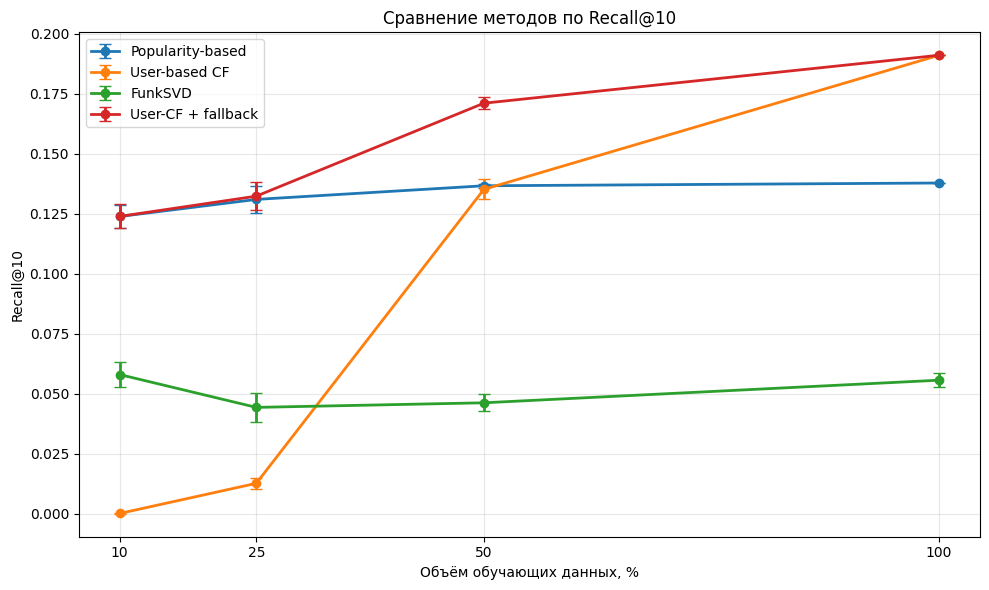

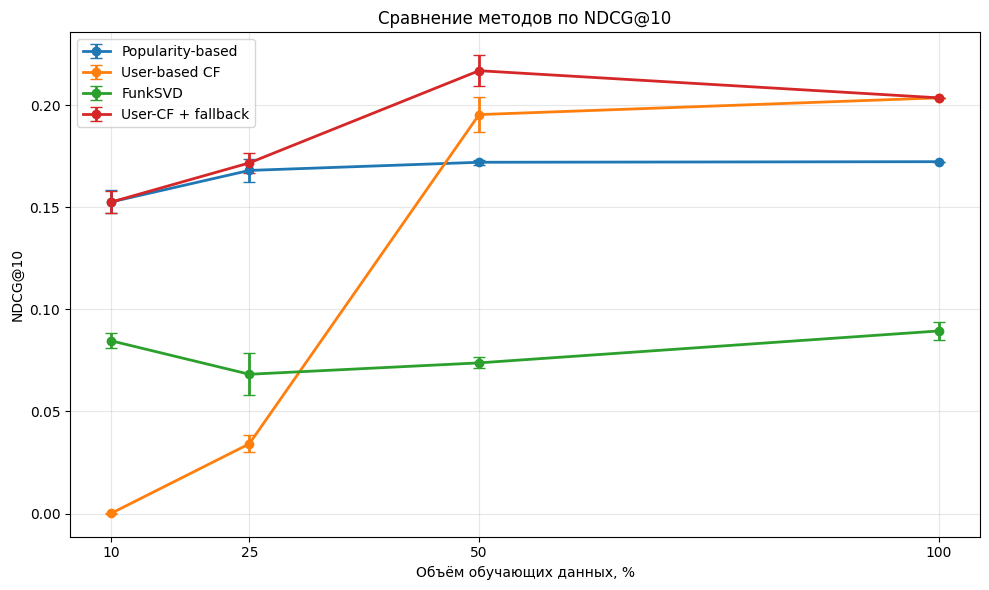

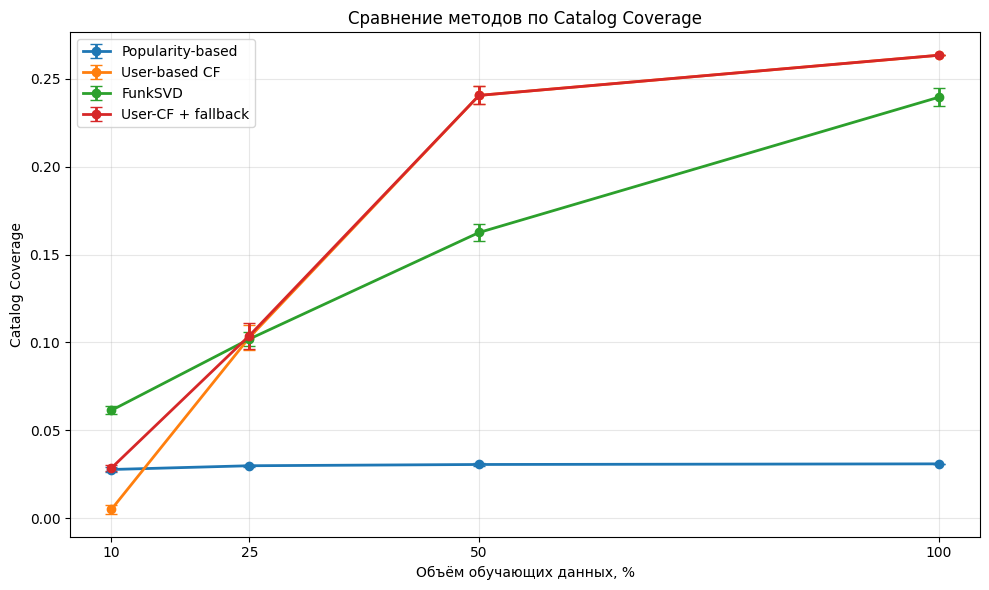

In [15]:
def plot_metric(summary, mean_col, std_col, title, ylabel):
    plt.figure(figsize=(10, 6))

    for method in METHODS:
        method_data = (
            summary[summary["method"] == method]
            .sort_values("share_percent")
        )
        if method_data.empty:
            continue

        plt.errorbar(
            method_data["share_percent"],
            method_data[mean_col],
            yerr=method_data[std_col].fillna(0),
            marker="o",
            capsize=4,
            linewidth=2,
            label=method
        )

    plt.title(title)
    plt.xlabel("Объём обучающих данных, %")
    plt.ylabel(ylabel)
    plt.xticks([10, 25, 50, 100])
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_metric(
    metric_summary, "recall_mean", "recall_std",
    "Сравнение методов по Recall@10", "Recall@10"
)

plot_metric(
    metric_summary, "ndcg_mean", "ndcg_std",
    "Сравнение методов по NDCG@10", "NDCG@10"
)

plot_metric(
    coverage_summary, "coverage_mean", "coverage_std",
    "Сравнение методов по Catalog Coverage", "Catalog Coverage"
)

## 16. Статистическое сравнение методов

Сравниваются все шесть пар методов для каждой доли данных отдельно. Для каждого пользователя метрики сначала усредняются по пяти повторам, затем выполняется парный критерий Уилкоксона. Bootstrap-интервалы рассчитываются для средней парной разности.

Поправка Холма применяется к общему семейству из 48 проверок (6 пар × 4 доли × 2 метрики), что соответствует описанной в отчёте схеме множественных сравнений.

In [16]:
def bootstrap_mean_ci(values, n_boot=5000, confidence=0.95, random_state=SEED):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(random_state)
    indices = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[indices].mean(axis=1)
    alpha = 1 - confidence
    return (
        float(np.quantile(means, alpha / 2)),
        float(np.quantile(means, 1 - alpha / 2))
    )


def pairwise_tests(results, metric_name):
    user_means = (
        results.groupby(["share_percent", "method", "user_id"])[metric_name]
        .mean()
        .reset_index()
    )

    rows = []
    method_pairs = list(combinations(METHODS, 2))

    for share in sorted(user_means["share_percent"].unique()):
        subset = user_means[user_means["share_percent"] == share]
        pivot = subset.pivot(
            index="user_id", columns="method", values=metric_name
        )

        for method_a, method_b in method_pairs:
            pair = pivot[[method_a, method_b]].dropna()
            differences = (pair[method_a] - pair[method_b]).to_numpy()

            if len(differences) == 0 or np.allclose(differences, 0):
                statistic, p_value = 0.0, 1.0
            else:
                test = wilcoxon(
                    pair[method_a],
                    pair[method_b],
                    alternative="two-sided",
                    zero_method="wilcox",
                    method="auto"
                )
                statistic = float(test.statistic)
                p_value = float(test.pvalue)

            ci_low, ci_high = bootstrap_mean_ci(
                differences,
                random_state=SEED + share + sum(map(ord, method_a + method_b))
            )

            rows.append({
                "share_percent": share,
                "metric": metric_name,
                "method_a": method_a,
                "method_b": method_b,
                "n_users": len(pair),
                "mean_difference_a_minus_b": float(np.mean(differences)),
                "ci_95_low": ci_low,
                "ci_95_high": ci_high,
                "wilcoxon_statistic": statistic,
                "p_value": p_value,
            })

    return pd.DataFrame(rows)


recall_tests = pairwise_tests(results_df, "recall_at_10")
ndcg_tests = pairwise_tests(results_df, "ndcg_at_10")

all_tests = pd.concat([recall_tests, ndcg_tests], ignore_index=True)
all_tests["p_holm"] = multipletests(
    all_tests["p_value"].to_numpy(),
    alpha=0.05,
    method="holm"
)[1]
all_tests["significant_holm_005"] = all_tests["p_holm"] < 0.05

recall_tests = all_tests[all_tests["metric"] == "recall_at_10"].copy()
ndcg_tests = all_tests[all_tests["metric"] == "ndcg_at_10"].copy()

display(all_tests.round(5))

,share_percent,metric,method_a,method_b,n_users,mean_difference_a_minus_b,ci_95_low,ci_95_high,wilcoxon_statistic,p_value,p_holm,significant_holm_005
0,10,recall_at_10,Popularity-based,User-based CF,929,0.12371,0.11506,0.13305,71.0,0.00000,0.00000,True
1,10,recall_at_10,Popularity-based,FunkSVD,929,0.06587,0.05702,0.07462,61206.5,0.00000,0.00000,True
2,10,recall_at_10,Popularity-based,User-CF + fallback,929,-0.00004,-0.00014,0.00003,2.0,0.59298,1.00000,False
3,10,recall_at_10,User-based CF,FunkSVD,929,-0.05785,-0.06228,-0.05353,190.5,0.00000,0.00000,True
4,10,recall_at_10,User-based CF,User-CF + fallback,929,-0.12375,-0.13283,-0.11486,0.0,0.00000,0.00000,True
5,10,recall_at_10,FunkSVD,User-CF + fallback,929,-0.06590,-0.07490,-0.05666,61356.5,0.00000,0.00000,True
6,25,recall_at_10,Popularity-based,User-based CF,929,0.11827,0.10930,0.12769,2544.5,0.00000,0.00000,True
7,25,recall_at_10,Popularity-based,FunkSVD,929,0.08663,0.07732,0.09646,42648.0,0.00000,0.00000,True
8,25,recall_at_10,Popularity-based,User-CF + fallback,929,-0.00136,-0.00229,-0.00042,12497.0,0.00045,0.00407,True
9,25,recall_at_10,User-based CF,FunkSVD,929,-0.03164,-0.03553,-0.02810,23001.5,0.00000,0.00000,True


## 17. Дополнительный анализ полноты рекомендательных списков

In [17]:
incomplete_summary = (
    incomplete_df.groupby("share_percent")
    .agg(
        mean_incomplete_users=("users_with_incomplete_list", "mean"),
        mean_incomplete_share=("incomplete_share", "mean")
    )
    .reset_index()
)
display(incomplete_summary.round(4))

,share_percent,mean_incomplete_users,mean_incomplete_share
0,10,929.0,1.0000
1,25,928.6,0.9996
2,50,427.2,0.4598
3,100,1.0,0.0011


## 18. Итоговая таблица для отчёта

In [18]:
final_table = metric_summary.merge(
    coverage_summary,
    on=["share_percent", "method"],
    how="left"
)

final_table["Recall@10"] = final_table.apply(
    lambda r: f"{r['recall_mean']:.4f} ± {r['recall_std']:.4f}", axis=1
)
final_table["NDCG@10"] = final_table.apply(
    lambda r: f"{r['ndcg_mean']:.4f} ± {r['ndcg_std']:.4f}", axis=1
)
final_table["Catalog Coverage"] = final_table.apply(
    lambda r: f"{r['coverage_mean']:.4f} ± {r['coverage_std']:.4f}", axis=1
)

report_table = final_table[
    ["share_percent", "method", "Recall@10", "NDCG@10", "Catalog Coverage"]
].rename(columns={
    "share_percent": "Объём данных, %",
    "method": "Метод"
})

display(report_table)

,"Объём данных, %",Метод,Recall@10,NDCG@10,Catalog Coverage
0,10,FunkSVD,0.0579 ± 0.0054,0.0846 ± 0.0036,0.0614 ± 0.0023
1,10,Popularity-based,0.1238 ± 0.0049,0.1527 ± 0.0056,0.0277 ± 0.0014
2,10,User-CF + fallback,0.1238 ± 0.0050,0.1526 ± 0.0054,0.0285 ± 0.0016
3,10,User-based CF,0.0001 ± 0.0001,0.0002 ± 0.0002,0.0050 ± 0.0024
4,25,FunkSVD,0.0443 ± 0.0060,0.0682 ± 0.0102,0.1019 ± 0.0038
5,25,Popularity-based,0.1309 ± 0.0057,0.1681 ± 0.0058,0.0298 ± 0.0007
6,25,User-CF + fallback,0.1323 ± 0.0059,0.1717 ± 0.0049,0.1038 ± 0.0073
7,25,User-based CF,0.0126 ± 0.0022,0.0341 ± 0.0042,0.1027 ± 0.0070
8,50,FunkSVD,0.0462 ± 0.0036,0.0738 ± 0.0026,0.1625 ± 0.0050
9,50,Popularity-based,0.1366 ± 0.0008,0.1721 ± 0.0011,0.0306 ± 0.0009


## 19. Проверки корректности результатов

Проверяем наличие четырёх методов во всех сценариях, отсутствие рекомендаций из полной истории, корректность диапазонов метрик и ожидаемое число строк.

In [19]:
expected_methods = set(METHODS)
assert set(results_df["method"].unique()) == expected_methods
assert set(metric_summary["method"].unique()) == expected_methods
assert set(coverage_summary["method"].unique()) == expected_methods

expected_combinations = len(DATA_SHARES) * N_REPEATS * len(METHODS)
actual_combinations = results_df[
    ["share_percent", "repeat", "method"]
].drop_duplicates().shape[0]
assert actual_combinations == expected_combinations

assert results_df["recall_at_10"].between(0, 1).all()
assert results_df["ndcg_at_10"].between(0, 1).all()
assert coverage_df["catalog_coverage"].between(0, 1).all()

for share in DATA_SHARES:
    for repeat in range(1, N_REPEATS + 1):
        part = results_df[
            (results_df["share_percent"] == int(share * 100))
            & (results_df["repeat"] == repeat)
        ]
        assert set(part["method"].unique()) == expected_methods

print("Проверки пройдены.")
print("Число пользовательских строк:", len(results_df))
print("Число комбинаций доля × повтор × метод:", actual_combinations)

Проверки пройдены.
Число пользовательских строк: 74320
Число комбинаций доля × повтор × метод: 80


## 20. Экспорт результатов в Excel

Сохраняются пользовательские метрики, покрытие, сводные таблицы, статистические тесты и итоговая таблица для отчёта.

In [20]:
output_path = "results_recommender_experiment_4_methods.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    results_df.to_excel(writer, sheet_name="User metrics", index=False)
    coverage_df.to_excel(writer, sheet_name="Coverage by repeat", index=False)
    metric_summary.to_excel(writer, sheet_name="Metric summary", index=False)
    coverage_summary.to_excel(writer, sheet_name="Coverage summary", index=False)
    all_tests.to_excel(writer, sheet_name="Pairwise tests", index=False)
    incomplete_df.to_excel(writer, sheet_name="Incomplete lists", index=False)
    report_table.to_excel(writer, sheet_name="Report table", index=False)

print(f"Файл сохранён: {output_path}")

Файл сохранён: results_recommender_experiment_4_methods.xlsx


## 21. Методика эксперимента: текст для отчёта

В эксперименте используется набор MovieLens 100K. Оценки каждого пользователя разделяются на обучающую и тестовую части в соотношении 80/20. Релевантными считаются фильмы с оценками 4 и 5. Пользователи без релевантных фильмов в тестовой части не участвуют в расчёте метрик.

Для моделирования ограниченного объёма пользовательских данных из обучающей части отдельно для каждого пользователя случайным образом сохраняются 10%, 25%, 50% или 100% оценок. При сокращении сохраняется не менее одной оценки. Каждый сценарий с долей менее 100% повторяется пять раз с различными фиксированными значениями генератора случайных чисел.

Сравниваются четыре метода: Popularity-based, User-based Collaborative Filtering, FunkSVD и User-CF с дополнением неполных списков популярными фильмами. В User-based CF используется косинусное сходство пользователей, не более 20 ближайших соседей и минимальный порог в пять соседей, оценивших фильм. FunkSVD реализован на основе регуляризованной матричной факторизации с 50 скрытыми факторами, скоростью обучения 0,01, коэффициентом регуляризации 0,02 и 20 эпохами обучения. В варианте User-CF + fallback неполный персональный список дополняется фильмами из рейтинга популярности.

Во всех сценариях фильмы, присутствующие в полной обучающей истории пользователя, исключаются из рекомендаций. Это правило не зависит от доли данных, используемой для обучения модели. Качество оценивается с помощью Recall@10 и NDCG@10, охват каталога — с помощью Catalog Coverage. Для проверки различий между методами используются парные критерии Уилкоксона по пользовательским средним за пять повторов и поправка Холма на множественные сравнения.